# Schematic figures: SHMR, formation time, galaxy occupation

Three stylistically matched schematics (DejaVu Sans + mathtext, 16 pt axis labels,
12 pt inward ticks, blue band palette, grey annotations, boxed symbols).

1. **SHMR** — low-mass slope $\alpha$ and scatter $\sigma$ (original figure).
2. **$z_{50}$ vs $M_{\rm vir}$** — halo half-mass formation redshift, MW-scaled, schematic.
3. **Galaxy occupation fraction** — $f_{\rm gal}(M_{\rm peak})$, illustrating $M_{50}$.

All numbers are illustrative, not fits.

In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch
from scipy.special import erf
from scipy.stats import gaussian_kde

# ---------------------------------------------------------------- shared style
LABEL_FS, TICK_FS = 16, 12
C_LINE, C_1S, C_2S = "#2a78d6", "#bfd6f1", "#e7f0fa"
C_SIG, C_ALP, C_DASH = "#666666", "#666666", "#999999"
FIGSIZE = (4, 4)

def style_axes(ax, xlabel, ylabel, log=False):
    if log:
        ax.set_xscale("log"); ax.set_yscale("log")
    ax.set_xlabel(xlabel, fontsize=LABEL_FS)
    ax.set_ylabel(ylabel, fontsize=LABEL_FS)
    ax.tick_params(which="both", direction="in", labelsize=TICK_FS, pad=6)
    for s in ("top", "right"):
        ax.spines[s].set_visible(False)

def symbol_box(ax, xc, yc, text, ec, w=0.155, h=0.24, fs=36):
    """Rounded white box with a large symbol, in axes-fraction coords."""
    ax.add_patch(FancyBboxPatch((xc - w/2, yc - h/2), w, h,
                                boxstyle="round,pad=0,rounding_size=0.04",
                                transform=ax.transAxes, fc="white", ec=ec,
                                lw=1.6, zorder=5))
    ax.text(xc, yc, text, transform=ax.transAxes, ha="center", va="center",
            fontsize=fs, zorder=6)

FIGDIR = "figures/"
os.makedirs(FIGDIR, exist_ok=True)

def save(fig, stem):
    fig.tight_layout()
    fig.savefig(f"{FIGDIR}{stem}.pdf", bbox_inches="tight")

## 1. SHMR schematic ($\alpha$, $\sigma$)

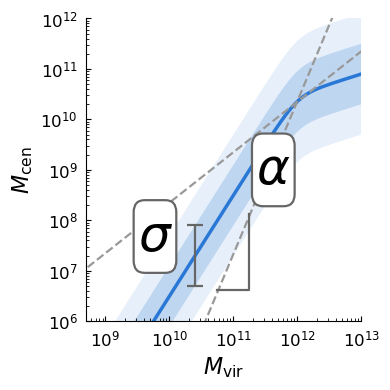

In [2]:
SIGMA_BOX = (0.25, 0.28)
ALPHA_BOX = (0.68, 0.50)
SIGMA_BAR_LOGM = 10.4
ALPHA_TRI = dict(x0=10.75, x1=11.25, y0=6.62, y1=8.13)

def log_mstar(x, xp=12.0, yp=10.5, alpha=2.0, beta=0.4, delta=0.3):
    """Smoothly broken power law in log space: slope alpha below xp, beta above."""
    u = x - xp
    return yp + beta * u - (alpha - beta) * delta * np.log10(1 + 10 ** (-u / delta))

sigma = 0.6
x = np.linspace(8, 13, 500)
y = log_mstar(x)

fig, ax = plt.subplots(figsize=FIGSIZE)
ax.fill_between(10**x, 10**(y - 2*sigma), 10**(y + 2*sigma), color=C_2S, lw=0)
ax.fill_between(10**x, 10**(y - sigma),   10**(y + sigma),   color=C_1S, lw=0)
ax.plot(10**x, 10**y, color=C_LINE, lw=2.5)

ax.plot(10**x, 10**(6.35 + 1.0 * (x - 8)), ls="--", color=C_DASH, lw=1.6)
ax.plot(10**x, 10**(5.0 + 3.03 * (x - 10.23)), ls="--", color=C_DASH, lw=1.6)

xs = SIGMA_BAR_LOGM
ax.errorbar(10**xs, 10**log_mstar(xs),
            yerr=[[10**log_mstar(xs) - 10**(log_mstar(xs) - sigma)],
                  [10**(log_mstar(xs) + sigma) - 10**log_mstar(xs)]],
            color=C_SIG, lw=1.6, capsize=6, capthick=1.6)

t = ALPHA_TRI
ax.plot([10**t["x0"], 10**t["x1"], 10**t["x1"]], [10**t["y0"], 10**t["y0"], 10**t["y1"]],
        color=C_ALP, lw=1.6)

symbol_box(ax, *SIGMA_BOX, r"$\sigma$", C_SIG)
symbol_box(ax, *ALPHA_BOX, r"$\alpha$", C_ALP)

ax.set_xlim(5e8, 1e13); ax.set_ylim(1e6, 1e12)
style_axes(ax, r"$M_{\rm vir}$", r"$M_{\rm cen}$", log=True)
save(fig, "shmr_schematic")
plt.show()

## 2. Formation time $z_{50}$ vs $M_{\rm vir}$

$z_{50}$ is the redshift at which the main progenitor first reached half its present-day mass.
Schematic only: a mock halo sample uniform in $\log M_{\rm vir}$ over the same
$10^{11}$–$10^{13}\,M_\odot$ range, with a median relation loosely
following N-body trends (low-mass halos form earlier; MW-mass halos have $z_{50}\sim1.2$–1.5)
and ~0.1 dex scatter in $\log(1+z_{50})$, skewed slightly toward late formers.
Filled contours enclose 68% and 95% of halos (same palette as the SHMR $1\sigma/2\sigma$ bands).

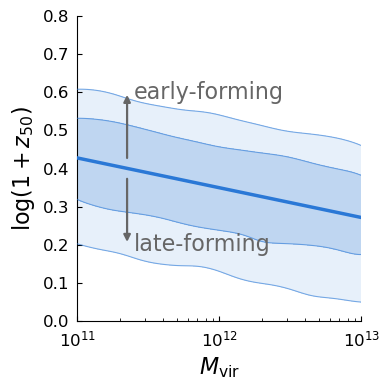

In [3]:
rng = np.random.default_rng(42)

def median_log1pz50(logm):
    """Schematic median log10(1+z50): ~0.66 (z50~3.6) at 1e8, ~0.35 (z50~1.25) at 1e12."""
    return 0.35 - 0.078 * (logm - 12.0)

N = 20000
logm = rng.uniform(10.8, 13.2, N)
# skew-normal-ish scatter: long tail to late formation (low z50)
eps = rng.normal(0, 1, N)
scat = np.where(eps < 0, 0.12, 0.09) * eps
ly = median_log1pz50(logm) + scat

# KDE on a grid -> density levels enclosing 68% / 95% of the sample
kde = gaussian_kde(np.vstack([logm, ly]), bw_method=0.18)
gx, gy = np.mgrid[10.8:13.2:240j, 0.0:1.0:240j]
dens = kde(np.vstack([gx.ravel(), gy.ravel()])).reshape(gx.shape)
d_sample = kde(np.vstack([logm[:4000], ly[:4000]]))
lev95, lev68 = np.percentile(d_sample, [5, 32])

fig, ax = plt.subplots(figsize=FIGSIZE)
# x: M_vir on a log axis (matches SHMR / occupation panels); y: log10(1+z50), linear
GX, GY = 10**gx, gy
ax.contourf(GX, GY, dens, levels=[lev95, lev68], colors=[C_2S], zorder=1)
ax.contourf(GX, GY, dens, levels=[lev68, dens.max()*1.01], colors=[C_1S], zorder=2)
ax.contour(GX, GY, dens, levels=[lev95, lev68], colors=[C_LINE], linewidths=0.8,
           alpha=0.6, zorder=3)

xm = np.linspace(11, 13, 200)
ax.plot(10**xm, median_log1pz50(xm), color=C_LINE, lw=2.5, zorder=4)

# early/late annotation arrow at fixed mass
XA = 11.35
y0 = median_log1pz50(XA)
for dy, lab in [(+0.2, "early-forming"), (-0.2, "late-forming")]:
    ax.annotate("", xy=(10**XA, y0 + dy), xytext=(10**XA, y0 + 0.02*np.sign(dy)),
                arrowprops=dict(arrowstyle="-|>", color=C_SIG, lw=1.6))
    ax.text(10**(XA + 0.05), y0 + dy, lab, ha="left", va="center", color=C_SIG, fontsize=LABEL_FS)

# symbol_box(ax, 0.80, 0.82, r"$z_{50}$", C_SIG, w=0.22, fs=30)

ax.set_xscale("log")
ax.set_xlim(1e11, 1e13); ax.set_ylim(0.0, 0.8)
style_axes(ax, r"$M_{\rm vir}$", r"$\log(1+z_{50})$")
save(fig, "z50_schematic")
plt.show()

## 3. Galaxy occupation fraction and $M_{50}$

$f_{\rm gal}(M_{\rm peak})$ is the fraction of halos of peak virial mass $M_{\rm peak}$ that host a
galaxy brighter than $M_V = 0$. Following the Nadler et al. parameterization (cf. Fig. 3, right),

$$f_{\rm gal}(M_{\rm peak}) = \frac{1}{2}\left[1 + \mathrm{erf}\left(\frac{\log M_{\rm peak} - \logM_{50}}{\sqrt{2}\,\sigma_{\rm gal}}\right)\right],$$

so $M_{50}$ is simply **the peak halo mass at which half of halos host a galaxy**,
and $\sigma_{\rm gal}$ sets how sharp the transition is. Values below are illustrative
($\logM_{50}=7.5$, $\sigma_{\rm gal}=0.25$ dex) with a schematic band for model spread.

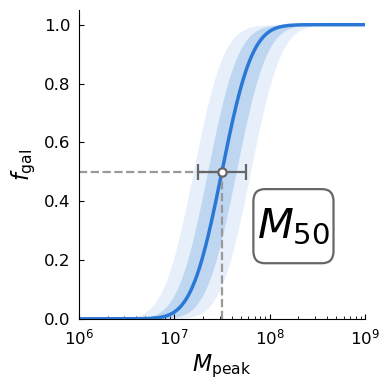

In [4]:
LOG_M50, SIG_GAL = 7.5, 0.25

def f_gal(logm, logm50=LOG_M50, s=SIG_GAL):
    return 0.5 * (1 + erf((logm - logm50) / (np.sqrt(2) * s)))

xm = np.linspace(6, 9, 500)

fig, ax = plt.subplots(figsize=FIGSIZE)
# schematic uncertainty: vary M50 by +/-0.15 and +/-0.3 dex
for dm, c in [(0.30, C_2S), (0.15, C_1S)]:
    ax.fill_between(10**xm, f_gal(xm, LOG_M50 + dm), f_gal(xm, LOG_M50 - dm), color=c, lw=0)
ax.plot(10**xm, f_gal(xm), color=C_LINE, lw=2.5)

# M50 guides: f = 0.5 horizontal + vertical drop to the axis
ax.plot([10**6, 10**LOG_M50], [0.5, 0.5], ls="--", color=C_DASH, lw=1.6)
ax.plot([10**LOG_M50, 10**LOG_M50], [0, 0.5], ls="--", color=C_DASH, lw=1.6)
ax.plot(10**LOG_M50, 0.5, "o", ms=6, mfc="white", mec=C_SIG, mew=1.6, zorder=6)

# sigma_gal: horizontal error bar spanning 16-84% of the transition
ax.errorbar(10**LOG_M50, 0.5, xerr=[[10**LOG_M50 - 10**(LOG_M50 - SIG_GAL)],
                                    [10**(LOG_M50 + SIG_GAL) - 10**LOG_M50]],
            fmt="none", color=C_SIG, lw=1.6, capsize=6, capthick=1.6, zorder=5)

symbol_box(ax, 0.75, 0.30, r"$M_{50}$", C_SIG, w=0.28, fs=30)

ax.set_xscale("log")
ax.set_xlim(1e6, 1e9); ax.set_ylim(0, 1.05)
style_axes(ax, r"$M_{\rm peak}$", r"$f_{\rm gal}$")
ax.set_xscale("log")
save(fig, "occupation_schematic")
plt.show()

## 4. LSST satellite luminosity function with Via limits

Cumulative luminosity function $N(<M_V)$ of Milky Way satellites ($r_{1/2}>10$ pc, $D<300$ kpc).
**Data, not schematic:** curves are the exact vector paths extracted from Tsiane et al. (2025,
arXiv:2504.16203) Fig. 8 source file (`plots/lsst_luminosity_function.pdf`), converted to data units
with the figure's own tick marks. Shown: the 10-yr LSST WFD prediction assuming perfect star/galaxy
separation (mean, $1\sigma$, $2\sigma$; Nadler et al. 2020 galaxy–halo model) and currently known
satellites in the LSST footprint (Pace 2024). Check: $N(<0)=88.9$ (paper: $89\pm20$), 36 known.

Via Dwarf Galaxy Survey limits (arXiv:2606.18332, §4.1.2):
- **DGS-Complete**, $M_V=-3.5$ — stated; every satellite within 300 kpc, $\geq5$ observable members.
- **DGS-Extreme**, $M_V\approx-2.2$ — *derived*: the 5-member ($G<23$) contour in Via Fig. 30 sits
  0.52 dex lower in $M_\star$ at 100 kpc than at 300 kpc (1.3 mag), anchored to $-3.5$ at 300 kpc.
  Via states no faint limit for DGS-Extreme, only $D\lesssim100$ kpc.

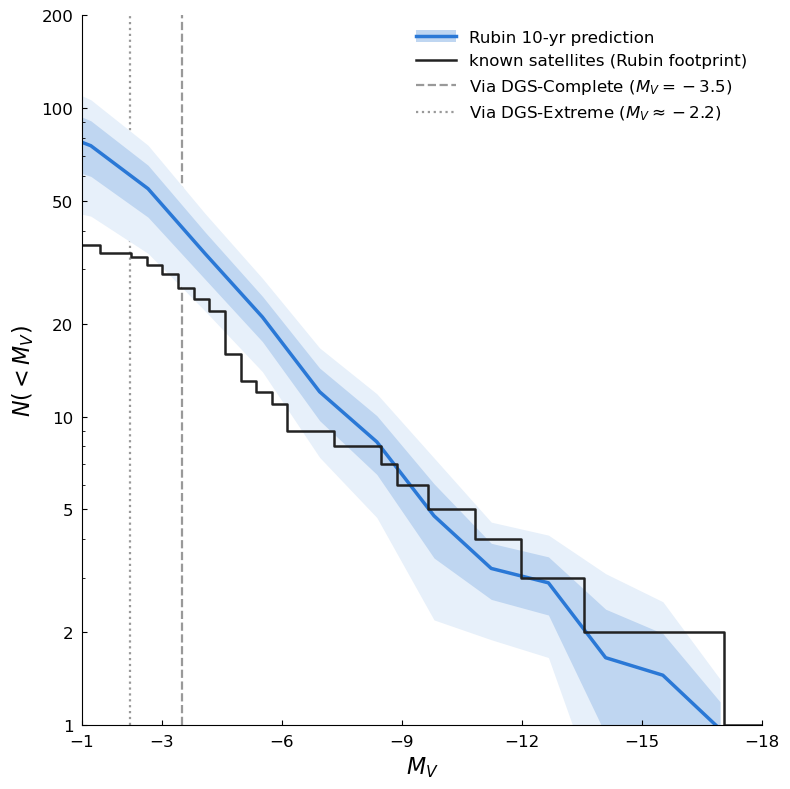

In [5]:
# ---- Tsiane+25 Fig. 8 paths, in PDF points (exact, from the arXiv source figure) ----
# x: M_V = 0 at 63.9 pt, -18 at 449.372432 pt (linear); y: N = 1 at 54 pt, 10 at 174.623889 pt (log10)
_X0, _XPERMAG = 63.9, (449.372432 - 63.9) / 18.0
_Y0, _YPERDEX = 54.0, 174.623889 - 54.0
pt_to_mv = lambda x: -(np.asarray(x) - _X0) / _XPERMAG
pt_to_n  = lambda y: 10 ** ((np.asarray(y) - _Y0) / _YPERDEX)

# LSST prediction, perfect star/galaxy separation (model grid, mean and 1/2-sigma envelopes)
LF_X = np.array([
    59.617, 90.21, 120.803, 151.396, 181.989, 212.582,
    243.175, 273.768, 304.361, 334.954, 365.547, 396.141,
    426.734])
LF_MEAN = np.array([
    289.111, 280.475, 263.68, 238.248, 213.514, 184.306,
    164.726, 135.821, 115.27, 109.646, 80.383, 73.5414,
    52.4583])
LF_1S_LO = np.array([
    275.782, 268.501, 252.554, 228.228, 203.916, 173.04,
    152.002, 119.337, 103.171, 97.0575, 50.3906, 49.7474,
    39.0057])
LF_1S_HI = np.array([
    299.728, 290.215, 272.852, 246.656, 221.623, 193.572,
    174.957, 148.341, 125.092, 119.789, 99.3359, 89.8433,
    63.1527])
LF_2S_LO = np.array([
    257.859, 252.954, 238.409, 215.826, 192.156, 158.669,
    135.159, 95.1484, 87.4116, 80.4529, -27.2267, 4.93266,
    20.8582])
LF_2S_HI = np.array([
    308.551, 298.424, 280.655, 253.899, 228.643, 201.443,
    183.512, 158.438, 133.36, 128.282, 113.224, 102.258,
    72.0296])

# currently known satellites in the LSST footprint (cumulative step; bin edges and levels)
KNOWN_X = np.array([
    454.093, 445.745, 437.397, 429.05, 420.702, 412.355,
    404.007, 395.66, 387.312, 378.965, 370.617, 362.27,
    353.922, 345.575, 337.227, 328.88, 320.532, 312.184,
    303.837, 295.489, 287.142, 278.794, 270.447, 262.099,
    253.752, 245.404, 237.057, 228.709, 220.362, 212.014,
    203.667, 195.319, 186.971, 178.624, 170.276, 161.929,
    153.581, 145.234, 136.886, 128.539, 120.191, 111.844,
    103.496, 95.1486, 86.8011, 78.4536, 70.106, 61.7585])
KNOWN_Y = np.array([
    54, 54, 54, 90.3114, 90.3114, 90.3114,
    90.3114, 90.3114, 90.3114, 90.3114, 90.3114, 90.3114,
    111.552, 111.552, 111.552, 111.552, 126.623, 126.623,
    126.623, 138.312, 138.312, 138.312, 147.864, 147.864,
    155.939, 162.934, 162.934, 162.934, 169.104, 169.104,
    169.104, 179.617, 184.175, 188.368, 199.246, 215.928,
    220.486, 224.68, 230.4, 233.894, 237.169, 238.733,
    238.733, 241.727, 241.727, 241.727, 241.727, 241.727])

# Via Dwarf Galaxy Survey limits (see markdown above)
VIA_COMPLETE = -3.5   # stated
VIA_EXTREME  = -2.2   # derived from Via Fig. 30
C_KNOWN = "#222222"

x = pt_to_mv(LF_X)
clip = lambda a: np.clip(pt_to_n(a), 0.5, None)   # N < 1 runs off the bottom, as in Tsiane+25

fig, ax = plt.subplots(figsize=(8, 8))
ax.fill_between(x, clip(LF_2S_LO), clip(LF_2S_HI), color=C_2S, lw=0)
ax.fill_between(x, clip(LF_1S_LO), clip(LF_1S_HI), color=C_1S, lw=0)
ax.plot(x, pt_to_n(LF_MEAN), color=C_LINE, lw=2.5)

kx, ky = pt_to_mv(KNOWN_X), pt_to_n(KNOWN_Y)
ax.plot(np.r_[kx[0], np.repeat(kx, 2)[1:], kx[-1]],
        np.r_[0.5, np.repeat(ky, 2)[:-1], 0.5], color=C_KNOWN, lw=1.8)

ax.axvline(VIA_COMPLETE, ls="--", color=C_DASH, lw=1.6, zorder=0)
ax.axvline(VIA_EXTREME,  ls=":",  color=C_DASH, lw=1.6, zorder=0)
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
handles = [(Patch(fc=C_2S, lw=0), Patch(fc=C_1S, lw=0), Line2D([], [], color=C_LINE, lw=2.5)),
           Line2D([], [], color=C_KNOWN, lw=1.8),
           Line2D([], [], ls="--", color=C_DASH, lw=1.6),
           Line2D([], [], ls=":",  color=C_DASH, lw=1.6)]
labels = ["Rubin 10-yr prediction", "known satellites (Rubin footprint)",
          r"Via DGS-Complete ($M_V=-3.5$)", r"Via DGS-Extreme ($M_V\approx-2.2$)"]
ax.legend(handles, labels, loc="upper right", frameon=False, fontsize=LABEL_FS * 0.75,
          handlelength=2.4)

ax.set_yscale("log")
ax.set_xlim(-1, -18); ax.set_ylim(1, 200)
ax.set_xticks([-1, -3, -6, -9, -12, -15, -18])
ax.set_yticks([1, 2, 5, 10, 20, 50, 100, 200])
ax.set_yticklabels(["1", "2", "5", "10", "20", "50", "100", "200"])
style_axes(ax, r"$M_V$", r"$N(<M_V)$")
save(fig, "lsst_lf_via")
plt.show()

## 5. Composite: inference pipeline figure

All four panels redrawn together at their final size in one $(8, 4)$ figure, so every panel shares
the same font sizes (`C_FS`, `C_TICK`, `C_NOTE`) and line widths instead of being rescaled PNGs.
(a) LSST luminosity function; (b) SHMR; (c) occupation fraction; (d) $z_{50}$. Uses the data and
functions defined in the cells above, so run those first. Saved as `figures/inference_pipeline.pdf`
at exactly 8 × 4 in (no `bbox_inches='tight'`).

Three layouts are available: `grid` (2 × 2 on the right, box in the fourth cell), `row_below` (wide row, box as a banner underneath) and `row_above` (banner on top, the current choice). `LAYOUT` picks which one is drawn and saved.

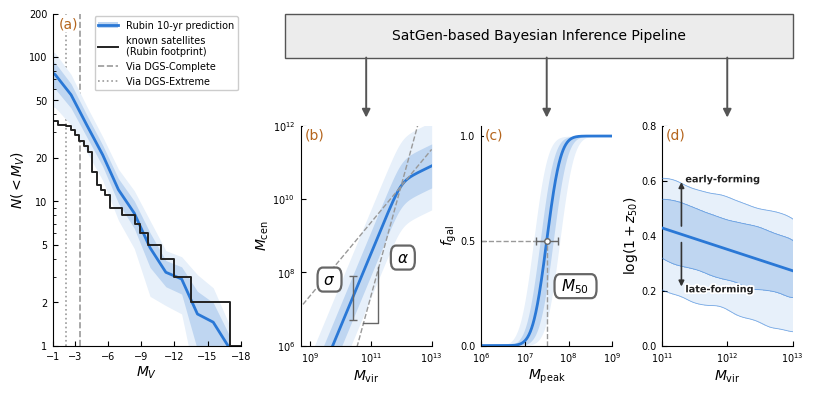

In [6]:
# ---- composite: LSST LF (a) + SHMR (b), occupation (c), z50 (d), fed by the SatGen pipeline box
# Every panel is redrawn here at its final size, with one set of font sizes, so nothing is rescaled.
from matplotlib.patches import FancyArrowPatch, Patch
from matplotlib.lines import Line2D
import matplotlib.patheffects as pe

C_FS, C_TICK = 10, 7            # axis labels / tick labels, all panels
C_NOTE       = 7                # legend and in-panel text, all panels
C_SYM        = 11               # boxed symbols (sigma, alpha, M50)
C_LETTER     = "#b5651d"        # panel letters
C_BOX_FC, C_BOX_EC = "#ececec", "#555555"

def comp_style(ax, xlabel, ylabel):
    ax.set_xlabel(xlabel, fontsize=C_FS, labelpad=2)
    ax.set_ylabel(ylabel, fontsize=C_FS, labelpad=1)
    ax.tick_params(which="both", direction="in", labelsize=C_TICK, pad=4)
    for s in ("top", "right"):
        ax.spines[s].set_visible(False)

def sym_box(ax, xc, yc, text, w_in, h_in, ec=C_SIG):
    # symbol_box with its size given in inches, so the boxes look the same in every layout
    p = ax.get_position(); fw, fh = ax.figure.get_size_inches()
    symbol_box(ax, xc, yc, text, ec, w=w_in / (p.width * fw), h=h_in / (p.height * fh), fs=C_SYM)

def letter(ax, txt, x=0.03, y=0.99):
    # top-left corner, inside the panel, on a white patch so it reads over guide lines
    ax.text(x, y, txt, transform=ax.transAxes, ha="left", va="top", fontsize=C_FS, color=C_LETTER,
            zorder=10, bbox=dict(boxstyle="square,pad=0.1", fc="white", ec="none"))

def panel_lf(ax):
    xl = pt_to_mv(LF_X)
    clip = lambda a: np.clip(pt_to_n(a), 0.5, None)
    ax.fill_between(xl, clip(LF_2S_LO), clip(LF_2S_HI), color=C_2S, lw=0)
    ax.fill_between(xl, clip(LF_1S_LO), clip(LF_1S_HI), color=C_1S, lw=0)
    ax.plot(xl, pt_to_n(LF_MEAN), color=C_LINE, lw=2.0)
    kx, ky = pt_to_mv(KNOWN_X), pt_to_n(KNOWN_Y)
    ax.plot(np.r_[kx[0], np.repeat(kx, 2)[1:], kx[-1]],
            np.r_[0.5, np.repeat(ky, 2)[:-1], 0.5], color=C_KNOWN, lw=1.4)
    ax.axvline(VIA_COMPLETE, ls="--", color=C_DASH, lw=1.2, zorder=0)
    ax.axvline(VIA_EXTREME,  ls=":",  color=C_DASH, lw=1.2, zorder=0)
    handles = [(Patch(fc=C_2S, lw=0), Patch(fc=C_1S, lw=0), Line2D([], [], color=C_LINE, lw=2.0)),
               Line2D([], [], color=C_KNOWN, lw=1.4),
               Line2D([], [], ls="--", color=C_DASH, lw=1.2),
               Line2D([], [], ls=":",  color=C_DASH, lw=1.2)]
    labels = ["Rubin 10-yr prediction", "known satellites (Rubin footprint)",
              r"Via DGS-Complete ($M_V=-3.5$)", r"Via DGS-Extreme ($M_V\approx-2.2$)"]
    # short labels keep the legend narrow (the Via M_V limits are in the caption and shown by the lines)
    labels = ["Rubin 10-yr prediction", "known satellites\n(Rubin footprint)", "Via DGS-Complete", "Via DGS-Extreme"]
    ax.legend(handles, labels, loc="upper right", frameon=True, framealpha=1, fontsize=C_NOTE,
              handlelength=2.0, borderaxespad=0.3)
    ax.set_yscale("log")
    ax.set_xlim(-1, -18); ax.set_ylim(1, 200)
    ax.set_xticks([-1, -3, -6, -9, -12, -15, -18])
    ax.set_yticks([1, 2, 5, 10, 20, 50, 100, 200])
    ax.set_yticklabels(["1", "2", "5", "10", "20", "50", "100", "200"])
    ax.yaxis.set_minor_formatter(plt.NullFormatter())
    comp_style(ax, r"$M_V$", r"$N(<M_V)$")

def panel_shmr(ax):
    xx = np.linspace(8, 13, 500); yy = log_mstar(xx)
    ax.fill_between(10**xx, 10**(yy - 2*sigma), 10**(yy + 2*sigma), color=C_2S, lw=0)
    ax.fill_between(10**xx, 10**(yy - sigma),   10**(yy + sigma),   color=C_1S, lw=0)
    ax.plot(10**xx, 10**yy, color=C_LINE, lw=2.0)
    ax.plot(10**xx, 10**(6.35 + 1.0 * (xx - 8)), ls="--", color=C_DASH, lw=1.0)
    ax.plot(10**xx, 10**(5.0 + 3.03 * (xx - 10.23)), ls="--", color=C_DASH, lw=1.0)
    xs = SIGMA_BAR_LOGM
    ax.errorbar(10**xs, 10**log_mstar(xs),
                yerr=[[10**log_mstar(xs) - 10**(log_mstar(xs) - sigma)],
                      [10**(log_mstar(xs) + sigma) - 10**log_mstar(xs)]],
                color=C_SIG, lw=1.0, capsize=3, capthick=1.0)
    t = ALPHA_TRI
    ax.plot([10**t["x0"], 10**t["x1"], 10**t["x1"]], [10**t["y0"], 10**t["y0"], 10**t["y1"]],
            color=C_ALP, lw=1.0)
    sym_box(ax, 0.22, 0.30, r"$\sigma$", 0.24, 0.24)
    sym_box(ax, 0.78, 0.40, r"$\alpha$", 0.24, 0.24, ec=C_ALP)
    ax.set_xscale("log"); ax.set_yscale("log")
    ax.set_xlim(5e8, 1e13); ax.set_ylim(1e6, 1e12)
    ax.set_xticks([1e9, 1e11, 1e13]); ax.set_yticks([1e6, 1e8, 1e10, 1e12])
    ax.minorticks_off()
    comp_style(ax, r"$M_{\rm vir}$", r"$M_{\rm cen}$")

def panel_occ(ax):
    xo = np.linspace(6, 9, 500)
    for dm, c in [(0.30, C_2S), (0.15, C_1S)]:
        ax.fill_between(10**xo, f_gal(xo, LOG_M50 + dm), f_gal(xo, LOG_M50 - dm), color=c, lw=0)
    ax.plot(10**xo, f_gal(xo), color=C_LINE, lw=2.0)
    ax.plot([10**6, 10**LOG_M50], [0.5, 0.5], ls="--", color=C_DASH, lw=1.0)
    ax.plot([10**LOG_M50, 10**LOG_M50], [0, 0.5], ls="--", color=C_DASH, lw=1.0)
    ax.errorbar(10**LOG_M50, 0.5, xerr=[[10**LOG_M50 - 10**(LOG_M50 - SIG_GAL)],
                                        [10**(LOG_M50 + SIG_GAL) - 10**LOG_M50]],
                fmt="none", color=C_SIG, lw=1.0, capsize=3, capthick=1.0, zorder=5)
    ax.plot(10**LOG_M50, 0.5, "o", ms=4, mfc="white", mec=C_SIG, mew=1.0, zorder=6)
    sym_box(ax, 0.72, 0.27, r"$M_{50}$", 0.42, 0.24)
    ax.set_xscale("log")
    ax.set_xlim(1e6, 1e9); ax.set_ylim(0, 1.05)
    ax.set_xticks([1e6, 1e7, 1e8, 1e9]); ax.set_yticks([0, 0.5, 1])
    ax.minorticks_off()
    comp_style(ax, r"$M_{\rm peak}$", r"$f_{\rm gal}$")

def panel_z50(ax):
    GX = 10**gx
    ax.contourf(GX, gy, dens, levels=[lev95, lev68], colors=[C_2S], zorder=1)
    ax.contourf(GX, gy, dens, levels=[lev68, dens.max()*1.01], colors=[C_1S], zorder=2)
    ax.contour(GX, gy, dens, levels=[lev95, lev68], colors=[C_LINE], linewidths=0.6, alpha=0.6, zorder=3)
    xz = np.linspace(11, 13, 200)
    ax.plot(10**xz, median_log1pz50(xz), color=C_LINE, lw=2.0, zorder=4)
    xa = 11.3; y0 = median_log1pz50(xa)
    pop = [pe.withStroke(linewidth=2.5, foreground="white")]      # white halo so the text reads over the bands
    for dy, lab in [(+0.2, "early-forming"), (-0.2, "late-forming")]:
        ax.annotate("", xy=(10**xa, y0 + dy), xytext=(10**xa, y0 + 0.02*np.sign(dy)),
                    arrowprops=dict(arrowstyle="-|>", color="#333333", lw=1.2, mutation_scale=8))
        ax.text(10**(xa + 0.06), y0 + dy, lab, ha="left", va="center", color="#222222", fontsize=C_NOTE,
                fontweight="semibold", path_effects=pop, zorder=6)
    ax.set_xscale("log")
    ax.set_xlim(1e11, 1e13); ax.set_ylim(0.0, 0.8)
    ax.set_yticks([0, 0.2, 0.4, 0.6, 0.8])
    ax.minorticks_off()
    comp_style(ax, r"$M_{\rm vir}$", r"$\log(1+z_{50})$")

# ---- layouts: three alternatives for an (8, 4) figure, all in figure fractions.
# Pick one with LAYOUT; it is saved as figures/inference_pipeline.pdf.
FIGSIZE_COMP = (8, 4)
LAYOUT = "row_above"       # "grid", "row_below" or "row_above"

def pipeline_box(fig, x, y, w, h, text="SatGen-based Bayesian\nInference Pipeline"):
    fig.patches.append(FancyBboxPatch((x, y), w, h, boxstyle="square,pad=0", transform=fig.transFigure,
                                      fc=C_BOX_FC, ec=C_BOX_EC, lw=1.0, zorder=1))
    fig.text(x + w/2, y + h/2, text, ha="center", va="center", fontsize=C_FS, linespacing=1.3)

def arrow(fig, start, end):
    fig.patches.append(FancyArrowPatch(start, end, transform=fig.transFigure, arrowstyle="-|>",
                                       mutation_scale=12, color=C_BOX_EC, lw=1.4, shrinkA=0, shrinkB=0))

def draw_panels(axA, axB, axC, axD):
    panel_lf(axA);   letter(axA, "(a)")
    panel_shmr(axB); letter(axB, "(b)")
    panel_occ(axC);  letter(axC, "(c)")
    panel_z50(axD);  letter(axD, "(d)")

def layout_grid():
    # (a) on the left; (b), (c), (d) and the pipeline box fill a 2 x 2 grid on the right
    fig = plt.figure(figsize=FIGSIZE_COMP)
    axA = fig.add_axes([0.070, 0.12, 0.33, 0.83])
    W, H = 0.215, 0.33
    axB = fig.add_axes([0.505, 0.62, W, H])
    axC = fig.add_axes([0.765, 0.62, W, H])
    axD = fig.add_axes([0.505, 0.12, W, H])
    draw_panels(axA, axB, axC, axD)
    bx, by, bw, bh = 0.775, 0.16, 0.20, 0.22
    pipeline_box(fig, bx, by, bw, bh, "SatGen-based\nBayesian Inference\nPipeline")
    arrow(fig, (bx + bw/2, by + bh), (bx + bw/2, 0.48))                 # up to (c)
    arrow(fig, (bx, by + bh/2), (0.735, by + bh/2))                      # left to (d)
    arrow(fig, (bx + 0.02, by + bh), (0.66, 0.48))                       # up-left to (b)
    return fig

def layout_row(box_below=True):
    # (a) on the left; (b), (c), (d) in one wide row; the pipeline box as a banner below (or above) them
    fig = plt.figure(figsize=FIGSIZE_COMP)
    axA = fig.add_axes([0.060, 0.12, 0.235, 0.83])    # (a) a little narrower ...
    X0, X1, GAP = 0.370, 0.985, 0.062                # ... so (b), (c), (d) share x = X0..X1; GAP holds each y label
    W = (X1 - X0 - 2 * GAP) / 3
    X = [X0 + n * (W + GAP) for n in range(3)]
    if box_below:
        Y, H, (by, bh) = 0.42, 0.53, (0.03, 0.11)
    else:
        Y, H, (by, bh) = 0.12, 0.55, (0.84, 0.11)
    axB, axC, axD = (fig.add_axes([x, Y, W, H]) for x in X)
    draw_panels(axA, axB, axC, axD)
    bx, bw = X[0] - 0.02, X1 - X[0] + 0.02
    pipeline_box(fig, bx, by, bw, bh, "SatGen-based Bayesian Inference Pipeline")
    for x in X:
        xc = x + W/2
        if box_below:
            arrow(fig, (xc, by + bh), (xc, Y - 0.15))                    # up to just under the x label
        else:
            arrow(fig, (xc, by), (xc, Y + H + 0.02))                     # down to just above the panel
    return fig

LAYOUTS = {"grid": layout_grid,
           "row_below": lambda: layout_row(box_below=True),
           "row_above": lambda: layout_row(box_below=False)}

# only the chosen layout is drawn and saved; set LAYOUT above to switch
fig = LAYOUTS[LAYOUT]()
fig.savefig(f"{FIGDIR}inference_pipeline.pdf")
plt.show()
